# Finding and Analzying Securities for Supporting Investment Decisions for 2025

## Introduction
The aim of this project is to gather information from the internet about suggested stocks, and analyse them.
**Objectives**:
- Define short-term investmen
- Use a webscraper to collect information about ssuggested securities
- Store the collected data in a database
- Select the 3 most frequently mentioned securities
- Prepare data for analysis
- Analyse data
- Summarize insights

### What are the benefits of investing in growth stocks?
Growth stocks are shares of companies that are expected to grow significantly faster than the overall market or their industry peers. These companies typically reinvest their earnings into the business to fuel further expansion, which often leads to impressive revenue and profit growth over time.1

### What will the analysis be focus on?
The analysis focuses on:
- visualize the most frequent words used when mentioning the specific stocks
- analyze the context around the stock's company; is it mostly positive or negative? Probably we don't want to invest in a company which has a negative publicity
- *volatility*: check the difference between the highest and lowest values within a day. Also, examine the difference between the opening and closing prices on the same day, and compare the opening price with the previous day's closing price to see the mood changes while the market is closed.
- *monotonity*: analyze the closing prices to determine the overall trend of the security

# SQL Database
Ceate a database to store data which will be analysed later. 

Considerations:
- Rarely, but it can happen that one company has more tickers
- When looking for tickers, it may not be possible to scrape company name and sector from the texts at first, so those are optional, can be filled with later searches
- Context is text scraped from where the company and/or sector was mentioned if exists
- Link is the URL of the website where the ccompany and/or sector was mentioned if exists

#### Tables

**stock_info**  
Ticker - text, primary key  
Company name - optional text,  
Sector - optional text,
Investopedia_link - optional text
  
**company_context**  
Company - text, primary key  
Context - optional text,  
link - optional text  

**sector_context**  
Sector - text, primary key  
Context - optional text,  
Link - optional text  






In [25]:
import sqlite3 as sql
import pandas as pd

# To avoid conflict with different versions
%config SqlMagic.style = '_DEPRECATED_DEFAULT'
%reload_ext sql

In [26]:
%sql sqlite:///stockAnalysis.db

#### Create tables

In [73]:
%%sql sqlite://
DROP TABLE stock_info;
DROP TABLE company_context;
DROP TABLE sector_context;

(sqlite3.OperationalError) no such table: stock_info
[SQL: DROP TABLE stock_info;]
(Background on this error at: https://sqlalche.me/e/20/e3q8)


In [74]:
%%sql sqlite://
CREATE TABLE IF NOT EXISTS stock_info(
    ticker VARCHAR(10) NOT NULL UNIQUE,
    company TEXT,
    sector VARCHAR(100),
    investopedia_link TEXT,
    PRIMARY KEY (ticker),
    FOREIGN KEY (company) REFERENCES company_context(company),
    FOREIGN KEY (sector) REFERENCES sector_context(sector)
);

Done.


[]

In [75]:
%%sql sqlite://
CREATE TABLE IF NOT EXISTS company_context(
    company TEXT NOT NULL UNIQUE,
    context TEXT,  
    link TEXT, 
    PRIMARY KEY (company)
);

Done.


[]

In [76]:
%%sql sqlite:///stockAnalysis.db
CREATE TABLE  IF NOT EXISTS sector_context(
    sector VARCHAR(100) NOT NULL UNIQUE,
    context TEXT,  
    link TEXT, 
    PRIMARY KEY (sector)
);

Done.


[]

##### Show created tables

In [77]:
%%sql
SELECT name
FROM sqlite_master
WHERE type='table';

 * sqlite:///stockAnalysis.db
Done.


name
stock_info
company_context
sector_context


# Gather data
I will gather data from the Internet using a Webscraper:
- Tickers mentioned as good investment oportunities, whenever possible I will also save the company and sector
- I will save context from atricles about the company, and the sector

#### Ethical Considerations
...

## Webscraper
- Gather data about AI stocks from a website
- Identify the tickers in the artices
- Store data gathered in a database


In [31]:
# Merge later once tested enough
import re
from urllib.request import urlopen
from urllib.request import Request
from urllib.error import HTTPError, URLError
# from urllib.parse import urljoin
from bs4 import BeautifulSoup
import time

# base_url = "https://www.mintos.com/blog/artificial-intelligence-stocks/"
# base_url = "https://money.usnews.com/investing/articles/up-and-coming-stocks-to-buy-in-2025"
base_url = "https://www.bing.com/search?q=best+stocks+to+invest+in+2025"
base_url = "https://www.investopedia.com/the-best-growth-stocks-8783031"


In [33]:
bs = get_bs_from_url()
# print(bs)

In [100]:
class webscraper:
    debug = False

    def get_bs_from_url(url = base_url):
        try:
            headers = {
                "User-Agent": "Mozilla/5.0 (Windows NT 10.0; Win64; x64) AppleWebKit/537.36 (KHTML, like Gecko) Chrome/131.0.0.0 Safari/537.36",
                # "Referer": "https://www.google.com/", # simulate Google search
                #"Connection": "keep-alive",
                #"Upgrade-Insecure-Requests": "1"
            }
            
            # To avoid 'Too many requests'
            time.sleep(5)
            
            response = urlopen(Request(url, headers=headers))
            return BeautifulSoup(response.read(), 'html.parser')

        except HTTPError as e:
            print(f"HTTP error: {e.code} - {e.reason}")
            return None
        
        except URLError as e:
            print(f"URL error: {e.reason}")
            return None 
    
    def scrape_ticker_data_from_investopedia(self, soup):
        bs = get_bs_from_url("https://www.investopedia.com/the-best-growth-stocks-8783031")
        if not soup:
            return []

       # Keressük azt a táblázatot, amelynek a fejlécében szerepel a "Stock" szó
        table = None
        for tbl in soup.find_all("table"):
            if tbl.find("th", string=lambda s: s and "stock" in s.lower()):
                table = tbl
                break

        if table:
            # First row of the table body contains the indexes
            first_row = table.find("tbody").find("tr")
            column_name_indexes = {}
            for i, td in enumerate(first_row.find_all("td", recurisive=False)):
                text = td.get_text(strip=True).lower()
                if "ticker" in text:
                    column_name_indexes["ticker"] = i
                elif "company" in text:
                    column_name_indexes["company"] = i
                elif "sector" in text:
                    column_name_indexes["sector"] = i
                i+=1

            all_ticker_data = []
            # Get data from table
            for row in first_row.find_next_siblings("tr"):
                ticker_data = {}
                cells = row.find_all("td")
                
                # Ticker has a link to the profile
                link = cells[column_name_indexes["ticker"]].find('a')
                if link:
                    ticker_data["investopedia_link"] = link.attrs['href']         
                
                # Extract data from each cell
                ticker_data["ticker"] = cells[column_name_indexes["ticker"]].get_text(strip=True)
                ticker_data["company"] = cells[column_name_indexes["company"]].get_text(strip=True)
                ticker_data["sector"] = cells[column_name_indexes["sector"]].get_text(strip=True)

                all_ticker_data.append(ticker_data)

            # print(*all_ticker_data, sep='\n')
            return all_ticker_data

In [102]:
my_scraper = webscraper()
my_scraper.scrape_ticker_data_from_investopedia(bs)

[{'investopedia_link': 'https://www.investopedia.com/markets/quote?tvwidgetsymbol=ACCD',
  'ticker': 'ACCD',
  'company': 'Accolade Inc.',
  'sector': 'Health Care'},
 {'investopedia_link': 'https://www.investopedia.com/markets/quote?tvwidgetsymbol=AKRO',
  'ticker': 'AKRO',
  'company': 'Akero Therapeutics Inc.',
  'sector': 'Health Care'},
 {'investopedia_link': 'https://www.investopedia.com/markets/quote?tvwidgetsymbol=OPFI',
  'ticker': 'OPFI',
  'company': 'OppFi Inc.',
  'sector': 'Financials'},
 {'investopedia_link': 'https://www.investopedia.com/markets/quote?tvwidgetsymbol=HEES',
  'ticker': 'HEES',
  'company': 'H&E Equipment Services Inc.',
  'sector': 'Financials'},
 {'investopedia_link': 'https://www.investopedia.com/markets/quote?tvwidgetsymbol=TEM',
  'ticker': 'TEM',
  'company': 'Tempus AI Inc.',
  'sector': 'Health Care'},
 {'investopedia_link': 'https://www.investopedia.com/markets/quote?tvwidgetsymbol=OKLO',
  'ticker': 'OKLO',
  'company': 'Oklo Inc.',
  'sector': 

In [82]:
import yfinance as yf
import pandas as pd

def get_securities_by_ticker_yahoo(tickers, start = "2024-01-01", end = "2024-12-31"):
    try:
        data =  yf.download(tickers, start, end)
        if data.empty:
            print(f"No data fetched for selected tickers:{tickers}, dates: {start} - {end}")
            return None
        return data
    except Exception as e:
        print(f"An error occured: {e}")
        return None

ModuleNotFoundError: No module named 'yfinance'

In [2]:
tickers = ["LLY", "NOW", "SHOP", "RIOT", "META"]
start_date = "2024-01-01"
end_date = "2024-12-31"
stock_results = get_securities_by_ticker_yahoo(tickers, start_date, end_date)
print(f"Dataset size: {stock_results.memory_usage(deep=True).sum() / 1e6} MB")
stock_results.head()

[*********************100%***********************]  5 of 5 completed

Dataset size: 0.052208 MB


Price            Close                                                  High  \
Ticker             LLY        META         NOW   RIOT       SHOP         LLY   
Date                                                                           
2024-01-02  589.334412  344.972229  687.520020  15.41  73.830002  589.851854   
2024-01-03  614.710999  343.159149  675.299988  15.04  71.820000  616.840658   
2024-01-04  611.526489  345.799042  671.869995  15.86  73.419998  633.330442   
2024-01-05  615.556946  350.610718  676.159973  14.83  74.510002  616.940234   
2024-01-08  623.000732  357.295197  696.260010  16.01  77.690002  623.030556   

Price                                                     ...        Open  \
Ticker            META         NOW       RIOT       SHOP  ...         LLY   
Date                                                      ...               
2024-01-02  351.816081  699.359985  17.110001  76.629997  ...  577.601423   
2024-01-03  346.625917  687.440002  15.230000  72.989998  ...  597.096636   
2024-01-04  346.825121  679.190002  16.080000  74.019997  ...  622.234432   
2024-01-05  352.154807  680.780029  15.565000  75.946999  ...  611.028975   
2024-01-08  357.613986  697.820007  16.200001  77.900002  ...  619.418116   

Price                                                  Volume            \
Ticker            META         NOW   RIOT       SHOP      LLY      META   
Date                                                                      
2024-01-02  349.983087  697.049988  17.07  76.440002  3226700  19042200   
2024-01-03  343.667218  675.760010  13.99  72.080002  5130300  15451100   
2024-01-04  343.189017  674.770020  15.31  71.629997  6272500  12099900   
2024-01-05  345.669570  672.130005  15.54  73.320000  2402500  13920700   
2024-01-08  353.350274  684.239990  15.08  74.779999  2453900  13890200   

Price                                    
Ticker          NOW      RIOT      SHOP  
Date                                     
2024-01-02  1130900  35508200  13134800  
2024-01-03   883000  29189700   9649900  
2024-01-04   914300  26736700  11927400  
2024-01-05   723600  26103900   9830200  
2024-01-08  1198200  40667000   8232000  

[5 rows x 25 columns]

## Data preparation
First, I analyze the data and check the following:
- Validate if the expected columns are present
- Validate data formats and their defined domains
- Handle any missing data
- Fill NaN values using a custom strategy
- inspect zero values if any

In [3]:
# validate the result type
type(stock_results)

pandas.core.frame.DataFrame

*Already in pandas dataframe, no need to convert*  
**Create a data validator class**

In [4]:
import numpy as np

idx = pd.IndexSlice

class data_validator:
    data = np.nan
    debugger = False
    
    def __init__(self, data):
        self.data = data
        
    @property
    def tickers(self):
        return list(self.data.columns.get_level_values(1).unique())
        
    @property
    def price_columns(self):
        return list(self.data.columns.get_level_values(0).unique())

    # Check tickers, and check price columns
    def check_expected_columns(self, tickers, pcols):
        print("\n---- Checking columns ----\n")
        missing_tickers = [col for col in tickers if col not in self.tickers]
        if missing_tickers:
            print(f"There are missing tickers:{missing_tickers}")
        
        missing_pcols = [col for col in pcols if col not in self.price_columns]
        if missing_pcols:
            print(f"There are missing price columns:{missing_pcols}")

        print(f"tickers in data: {self.tickers}\nPrice columns: {self.price_columns}")

    # validate date indexes, transform to datetime if needed
    def validate_date_rows(self, start, end):
        print("\n---- Checking date indexes ----\n")
        try:
            # Make sure start, end are in the good format
            start = pd.to_datetime(start)
            end = pd.to_datetime(end)

            # Check if index is DatetimeIndex and convert if not
            if type(self.data.index) != pd.DatetimeIndex:
                print("Date is not DateTimeIndex, converting..")
                self.data.index = pd.to_datetime(self.data.index)
            
            # ISO format is YYYY-MM-DD
            # https://pandas.pydata.org/docs/reference/api/pandas.Timestamp.isoformat.html
            out_of_range_dates = [d for d in self.data.index if d < start  or d > end]
            print(f"Dates out of the range: {out_of_range_dates}")

        except Exception as e:
            print(f"An error occured: {e}")

    # 1. validate numeric data, fix if possible, assign NaN if not possible
    # 2. check NaN values, and apply a custom strategy to fill them
    def validate_numeric_data_and_fill_nans(self):
        print("\n---- Validate numeric data and fill NaNs ----\n")
        for ticker in self.tickers:
            for col in self.price_columns:

                if self.debugger:
                    print("\n----------------------------")
                    print(f"Ticker:{ticker}, price column:{col}")  
                    print("----------------------------")
                    print(f"Data series:\n{self.data.loc[:, (col, ticker)]}")    

                ## Drop column if all values are NaN, and break from loop
                if self.data.loc[:, (col, ticker)].isna().all():
                    columns_to_drop = self.data.loc[:, idx[:, ticker]].columns
                    self.data.drop(columns = columns_to_drop, inplace=True)
                    print(f"columns dropped: {columns_to_drop}")
                    
                    if self.debugger:
                        print("data after dropping the column:")
                        print(self.data)

                    # Don't have columns for the ticker anymore
                    break
               
                if self.debugger:
                    print("\n---- Checking numeric data ----")

                # Check if not number
                if not pd.api.types.is_numeric_dtype(self.data.loc[:, (col, ticker)]):
                    non_numeric = self.data.loc[:, (col, ticker)][~pd.to_numeric(self.data.loc[:, (col, ticker)], errors='coerce').notna()]
                    print(f"Non-numeric type(s) found:\n{non_numeric}")
                    
                    # Tranform it
                    print("Transform to float if number, otherwise assign NaN")
                    self.data.loc[:, (col, ticker)] = self.data.loc[:, (col, ticker)].apply(pd.to_numeric, errors='coerce')

                    if self.debugger:
                        print(f"data after transformation:\n{self.data.loc[:, (col, ticker)]}")
        
                # Check if smaller than 0
                negative_values = [val for val in self.data.loc[:, (col, ticker)] if val < 0]
                if negative_values:
                    print(f"There are negative values:{negative_values}, transforming them to NaN")

                    # To avoid dtype incompatible, convert int to float
                    if np.issubdtype(self.data[(col, ticker)].dtype, np.integer):
                        print(f"Column for {ticker}:{col} is 'int' converting to 'float' for NaN compatibility")
                        self.data[(col, ticker)] = self.data[(col, ticker)].astype(float)
                     
                    # Transform negative to NaN
                    self.data.loc[:, (col, ticker)] = self.data.loc[:, (col, ticker)].apply(lambda val:np.nan if val < 0 else val)

                    if self.debugger:
                        print(f"data after transformation:\n{self.data.loc[:, (col, ticker)]}")

                # Now we only should have numeric or NaN values, so it should be fine to convert
                if not pd.api.types.is_numeric_dtype(self.data[(col, ticker)]):
                    print(f"\nThe original column for {ticker}:{col} isn't numeric but {self.data[(col, ticker)].dtype}")
                    self.data[(col, ticker)] = pd.to_numeric(self.data[(col, ticker)])
                    print(f"Converted to: {self.data[(col, ticker)].dtype}")

                # I want to analyzise volatility and monotonity, so I need to make sure I don't assign values that
                # might make a big difference (e.g. 0)
                if self.debugger:
                    print("\n---- Filling NaN values ----")
                
                # Check for NaN-s
                ## Use a specific filling strategy
                if self.data.loc[:, (col, ticker)].isna().any():
                    
                    ## If Volume is missing, use forward/backward filling to get data from previous/next days
                    if col == 'Volume':
                        print(f"NaN Volume is forward/backward filled for {ticker}")
                        self.data[(col, ticker)] = self.data[(col, ticker)].ffill().bfill().astype(float)

                    mask = self.data[(col, ticker)].isna()
                    ## If Close is missing, use Open and vice versa
                    if col == 'Close':
                        print(f"NaN Close is filled with Open for {ticker}")
                        self.data.loc[mask, ('Close', ticker)] = self.data.loc[mask, ('Open', ticker)].astype(float)
                    elif col == 'Open':
                        print(f"NaN Open is filled with Closed for {ticker}")
                        self.data.loc[mask, ('Open', ticker)] = self.data.loc[mask, ('Close', ticker)].astype(float)

                    ## Use the average if High / Low is missing
                    elif col in ['High','Low']:
                        print(f"NaN {col} is filled with average of Open and Close for {ticker}")
                        self.data.loc[mask, (col, ticker)] = ((self.data.loc[mask, ('Open', ticker)] + self.data.loc[mask, ('Close', ticker)])/2).astype(float)

                    if self.debugger:
                        print(f"\nData after filling NaNs:\n{self.data[(col, ticker)]}")

### Create a small dataset to test data validator class

In [5]:
import numpy as np

price_columns = ['Close','High','Low','Open','Volume']
sample_stocks = stock_results.loc[stock_results.index[:6], (price_columns, ['META', 'RIOT', 'LLY'])]

# Add NaNs and minuses
for i, col in enumerate(price_columns):
    sample_stocks.loc[sample_stocks.index[i:i+1], (col, 'META') ] = np.nan
    sample_stocks.loc[sample_stocks.index[i+2:i+3], (col, 'RIOT') ] = np.nan
    
    sample_stocks.loc[sample_stocks.index[i:i+1], (col, 'RIOT') ] = -1.0

# Covert column to object and insert string
sample_stocks[('Close', 'META')] = sample_stocks[('Close', 'META')].astype(object)
sample_stocks.loc['2024-01-08', ('Close', 'META')] = "alma"

# simulate missing Close and Volume datas for LLY
sample_stocks.loc[sample_stocks.index[:6], pd.IndexSlice[['Close', 'Volume'], 'LLY']] = np.nan

sample_stocks

Price            Close                   High                         \
Ticker            META   RIOT LLY        META       RIOT         LLY   
Date                                                                   
2024-01-02         NaN  -1.00 NaN  351.816081  17.110001  589.851854   
2024-01-03  343.159149  15.04 NaN         NaN  -1.000000  616.840658   
2024-01-04  345.799042    NaN NaN  346.825121  16.080000  633.330442   
2024-01-05  350.610718  14.83 NaN  352.154807        NaN  616.940234   
2024-01-08        alma  16.01 NaN  357.613986  16.200001  623.030556   
2024-01-09  356.069824  15.74 NaN  359.267631  16.170000  631.350050   

Price              Low                            Open                     \
Ticker            META    RIOT         LLY        META   RIOT         LLY   
Date                                                                        
2024-01-02  338.716128  15.310  576.248019  349.983087  17.07  577.601423   
2024-01-03  341.874050  13.750  595.902430  343.667218  13.99  597.096636   
2024-01-04         NaN  -1.000  610.302461  343.189017  15.31  622.234432   
2024-01-05  344.942368  14.367  607.237413         NaN  -1.00  611.028975   
2024-01-08  350.710334     NaN  606.640282  353.350274  15.08  619.418116   
2024-01-09  354.007694  15.520  620.701815  355.043745    NaN  627.060909   

Price           Volume                
Ticker            META      RIOT LLY  
Date                                  
2024-01-02  19042200.0  35508200 NaN  
2024-01-03  15451100.0  29189700 NaN  
2024-01-04  12099900.0  26736700 NaN  
2024-01-05  13920700.0  26103900 NaN  
2024-01-08         NaN        -1 NaN  
2024-01-09  13463900.0  22881600 NaN

In [6]:
validator = data_validator(sample_stocks)
validator.debugger = True
validator.validate_numeric_data_and_fill_nans()
validator.data


---- Validate numeric data and fill NaNs ----


----------------------------
Ticker:META, price column:Close
----------------------------
Data series:
Date
2024-01-02           NaN
2024-01-03    343.159149
2024-01-04    345.799042
2024-01-05    350.610718
2024-01-08          alma
2024-01-09    356.069824
Name: (Close, META), dtype: object

---- Checking numeric data ----
Non-numeric type(s) found:
Date
2024-01-02     NaN
2024-01-08    alma
Name: (Close, META), dtype: object
Transform to float if number, otherwise assign NaN
data after transformation:
Date
2024-01-02           NaN
2024-01-03    343.159149
2024-01-04    345.799042
2024-01-05    350.610718
2024-01-08           NaN
2024-01-09    356.069824
Name: (Close, META), dtype: object

The original column for META:Close isn't numeric but object
Converted to: float64

---- Filling NaN values ----
NaN Close is filled with Open for META

Data after filling NaNs:
Date
2024-01-02    349.983087
2024-01-03    343.159149
2024-01-04    345.7

Price            Close               High                    Low          \
Ticker            META   RIOT        META       RIOT        META    RIOT   
Date                                                                       
2024-01-02  349.983087  17.07  351.816081  17.110001  338.716128  15.310   
2024-01-03  343.159149  15.04  343.413184  14.515000  341.874050  13.750   
2024-01-04  345.799042  15.31  346.825121  16.080000  344.494029  15.310   
2024-01-05  350.610718  14.83  352.154807   6.915000  344.942368  14.367   
2024-01-08  353.350274  16.01  357.613986  16.200001  350.710334  15.545   
2024-01-09  356.069824  15.74  359.267631  16.170000  354.007694  15.520   

Price             Open             Volume              
Ticker            META   RIOT        META        RIOT  
Date                                                   
2024-01-02  349.983087  17.07  19042200.0  35508200.0  
2024-01-03  343.667218  13.99  15451100.0  29189700.0  
2024-01-04  343.189017  15.31  12099900.0  26736700.0  
2024-01-05  350.610718  14.83  13920700.0  26103900.0  
2024-01-08  353.350274  15.08  13920700.0  26103900.0  
2024-01-09  355.043745  15.74  13463900.0  22881600.0

#### Check test results
With debugging, it can be easily be followed how the transformations happen:  
**META / Close**
- 'alma' is tranformed to NaN
- column dtype is converted to float64
- 2024-01-02: NaN is filled with (2024-01-02) Open: 349.983087
- 2024-01-08: NaN is filled with (2024-01-08) Open: 353.350244

**META / High**
- 2024-01-03: NaN is filled with (META(Open) + META(Closed)) / 2: 343.413184

**META / Volume**
- 2024-01-08: NaN is filled with the previous day's value (2024-01-05): 13920700.0

**RIOT / Close**
- negative value (-1) is transformed to NaN
- 2024-01-02: NaN is filled with (2024-01-02) Open: 17.07
- 2024-01-04: NaN is filled with (2024-01-04) Open: 15.31

**LLY / Close**
- the column is empty for all rows, LLY ticker is dropped from the dataset

Everything looks correct

### Validate the original dataset

In [7]:
validator = data_validator(stock_results)
validator.check_expected_columns(tickers=tickers, pcols=price_columns)
validator.validate_date_rows(start_date, end_date)
validator.validate_numeric_data_and_fill_nans()


---- Checking columns ----

tickers in data: ['LLY', 'META', 'NOW', 'RIOT', 'SHOP']
Price columns: ['Close', 'High', 'Low', 'Open', 'Volume']

---- Checking date indexes ----

Dates out of the range: []

---- Validate numeric data and fill NaNs ----



In [8]:
# Check zero values
if (stock_results == 0).any().any() != False:
    stock_results[ stock_results == 0 ].stack()


There aren't any 0 values in the data

## Gather insights

In [9]:
volatility_per_ticker = {}
# Calculate an Y scale I can use for all data
all_diff_values = []
all_pct_diff_values = []
for ticker in tickers:

    highp = stock_results.loc[:, ('High', ticker)]
    lowp = stock_results.loc[:, ('Low', ticker)]
    openp =  stock_results.loc[:, ('Open',ticker)]
    closep = stock_results.loc[:, ('Close',ticker)]
    
    high_low_diff = highp - lowp
    all_diff_values.extend(high_low_diff.dropna().values)

    open_close_diff = openp - closep
    all_diff_values.extend(open_close_diff.dropna().values)
    
    nextopen_close_diff = openp.shift(1) - closep
    all_diff_values.extend(nextopen_close_diff.dropna().values)

    # high_low_diff_pct = ( (highp - lowp) / lowp.replace(0, np.nan)) * 100
    # all_pct_diff_values.extend(high_low_diff_pct.dropna().values)
    
    open_close_diff_pct = ( (openp - closep) / closep.replace(0, np.nan)) * 100
    all_pct_diff_values.extend(open_close_diff_pct.dropna().values)

    nextopen_close_diff_pct = ( (openp.shift(1) - closep) / closep.replace(0, np.nan)) * 100
    all_pct_diff_values.extend(nextopen_close_diff_pct.dropna().values)

    volatility_per_ticker[ticker] = {
        'high_low_diff': high_low_diff,
        'open_close_diff': open_close_diff,
        'nextopen_close_diff': nextopen_close_diff,
        # 'high_low_diff_pct': high_low_diff_pct,
        'open_close_diff_pct': open_close_diff_pct,
        'nextopen_close_diff_pct': nextopen_close_diff_pct
        }

y_diff_min, y_diff_max = min(all_diff_values), max(all_diff_values)
print(y_diff_min, y_diff_max)
y_pct_diff_min, y_pct_diff_max = min(all_pct_diff_values), max(all_pct_diff_values)
print(y_pct_diff_min, y_pct_diff_max)

-83.0400390625 91.5
-25.224491041533803 41.85848285613843


**Volatility: High-Low, and Open-Close Differences**

LLY -> AVG Volume: 3,214,811, AVG price:809


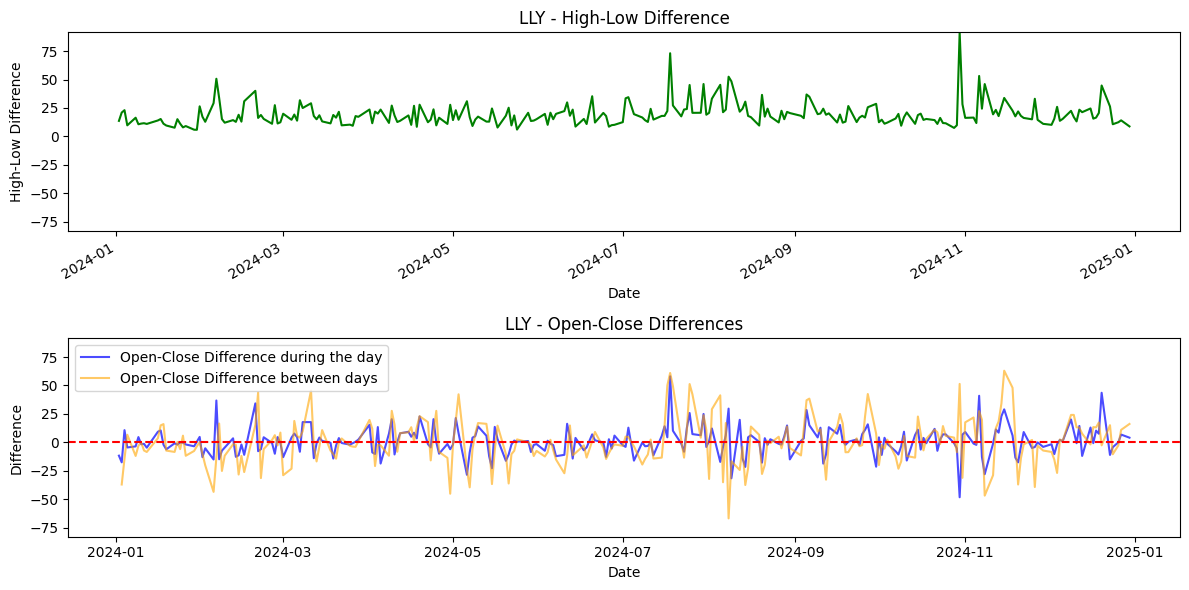

NOW -> AVG Volume: 1,273,478, AVG price:831


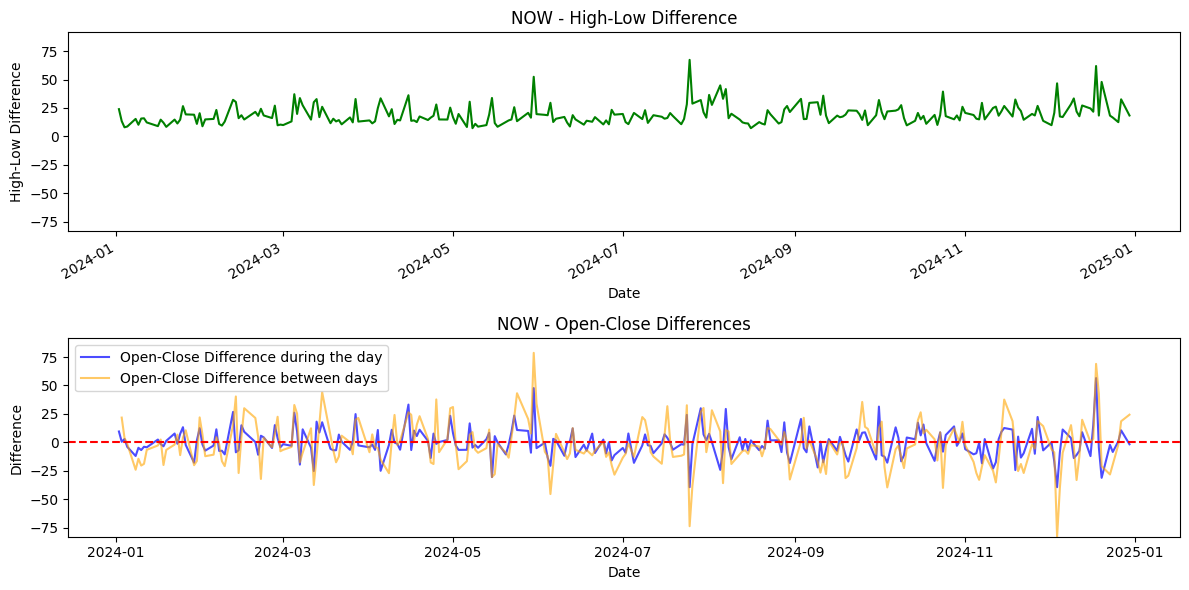

SHOP -> AVG Volume: 9,054,958, AVG price:77


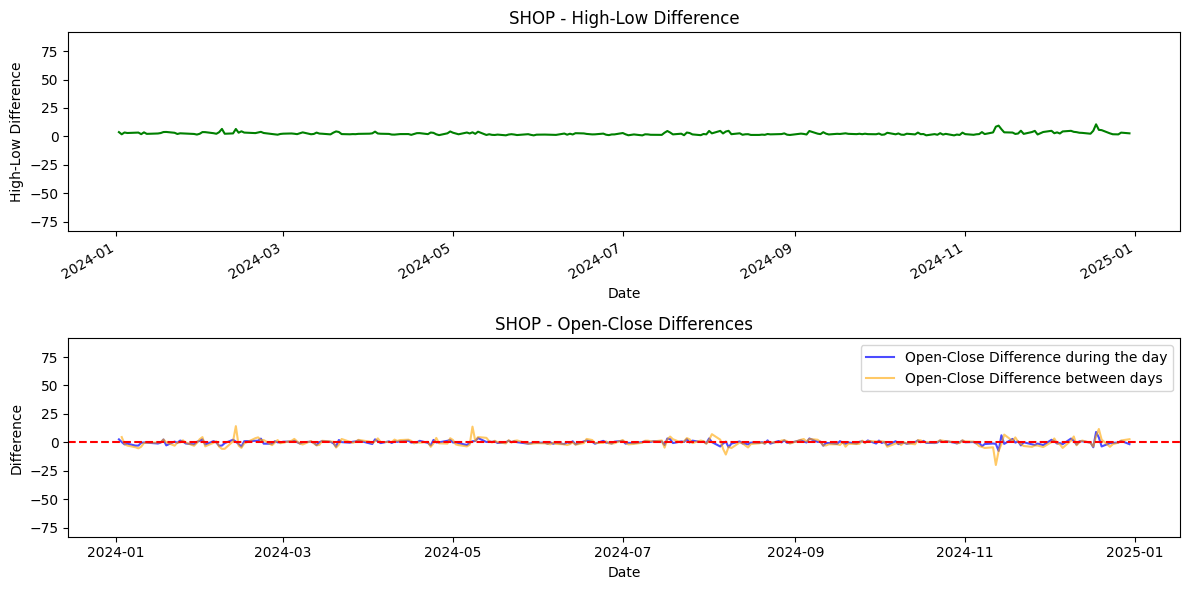

RIOT -> AVG Volume: 24,988,007, AVG price:10


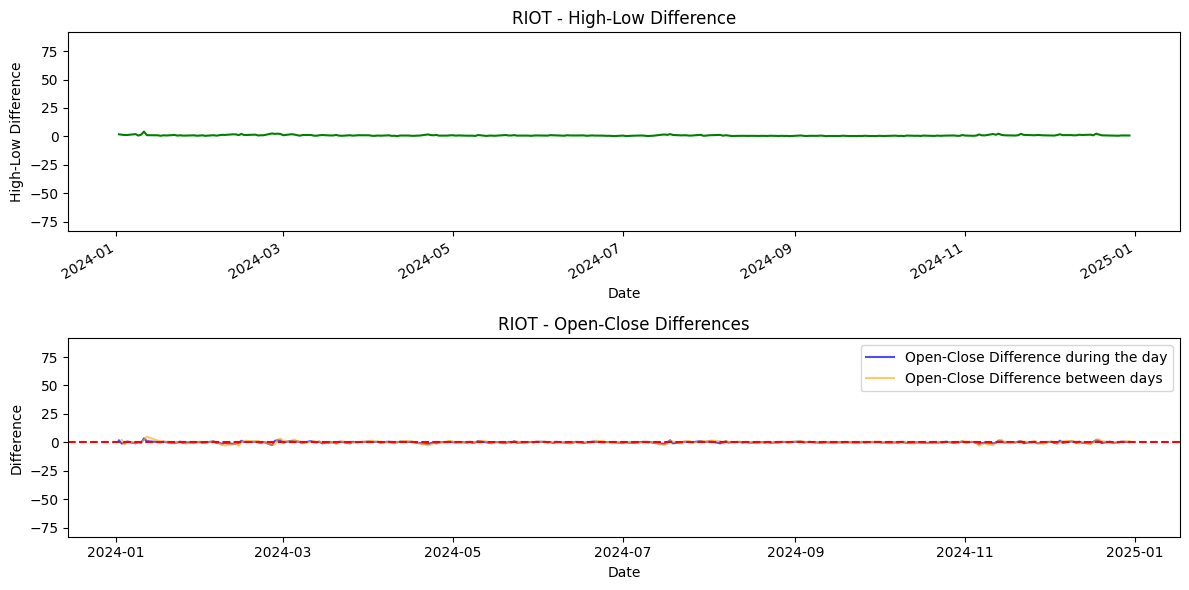

META -> AVG Volume: 14,717,144, AVG price:507


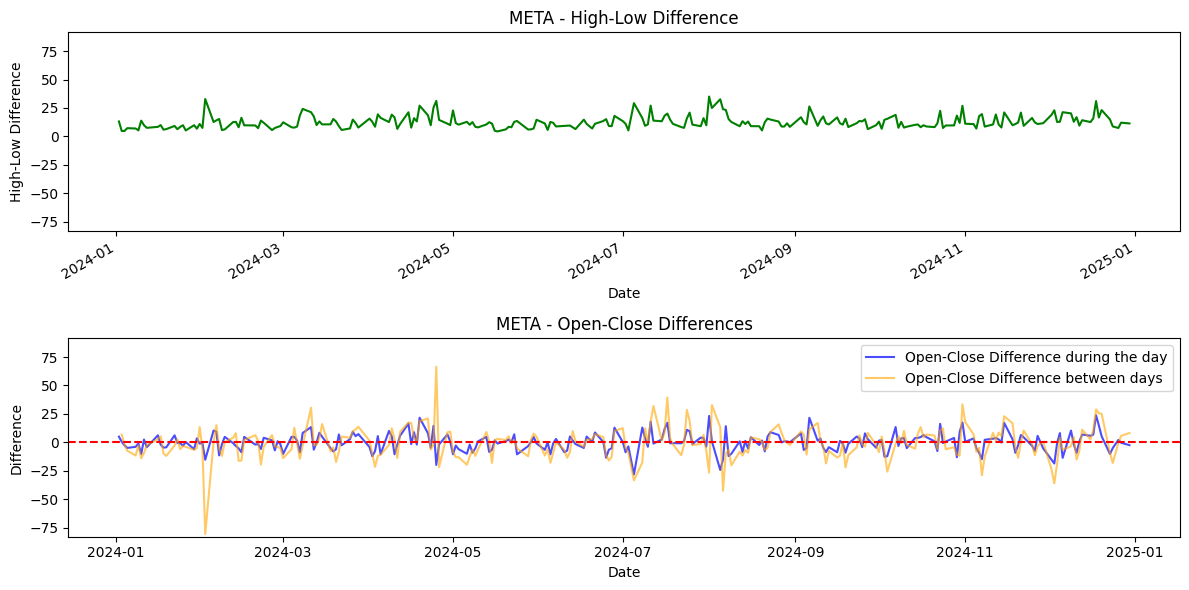

In [10]:
import matplotlib.pyplot as plt

idx = pd.IndexSlice

for ticker, data in volatility_per_ticker.items():
    mean_volume = format(int(stock_results.loc[:, idx['Volume', ticker]].mean()), ",")
    mean_close = format(int(stock_results.loc[:, idx['Close', ticker]].mean()), ",")
    print(f"{ticker} -> AVG Volume: {mean_volume}, AVG price:{mean_close}")

    plt.figure(figsize=(12,6))
    
    plt.subplot(2, 1, 1)
    data['high_low_diff'].plot(title=f"{ticker} - High-Low Difference", color="green")
    plt.ylabel("High-Low Difference")
    plt.ylim(y_diff_min, y_diff_max)

    plt.subplot(2, 1, 2)    
    # Overplay the two metrics
    plt.plot(data['open_close_diff'], label="Open-Close Difference during the day", color="blue", alpha=0.7)
    plt.plot(data['nextopen_close_diff'], label="Open-Close Difference between days", color="orange", alpha=0.6)
    plt.ylim(y_diff_min, y_diff_max)

    plt.title(f"{ticker} - Open-Close Differences")
    plt.ylabel("Difference")
    plt.xlabel("Date")
    plt.legend()

    plt.axhline(0, color='red', linestyle='--')
    plt.tight_layout()

    plt.show()

I would categorize the tickets into three groups:
- LLY and NOW have the biggest daily price changes
- META has a moderate change
- RIOT and SHOP have only minimum daily changes

RIOT has the highest volume of transactions, which means that only small transactions were created during the last year; the 10 dollars average price probably describes it correctly.  
In most of the cases we get a higher amplitudo from transactions made outside the market hours which makes me feel that people are more sensitive to price changes after the market is closed.  

Let's use the same data, but normalized to see the differences in percentage instead of dollars.

LLY -> AVG Volume: 3,214,811, AVG price:809


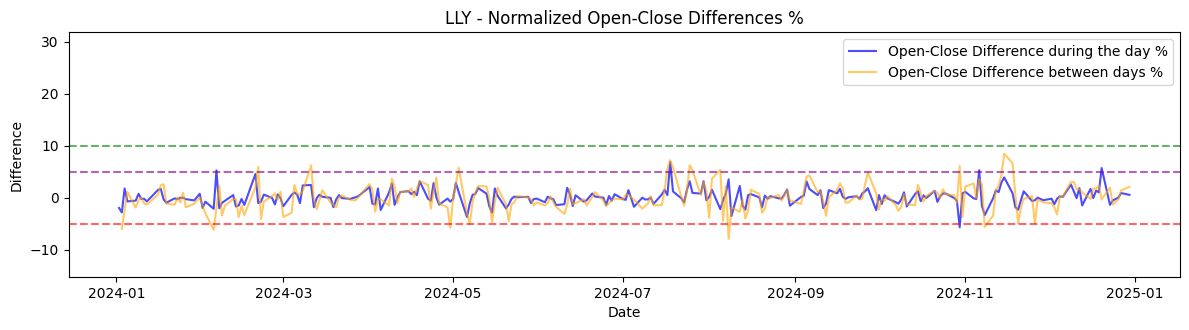

NOW -> AVG Volume: 1,273,478, AVG price:831


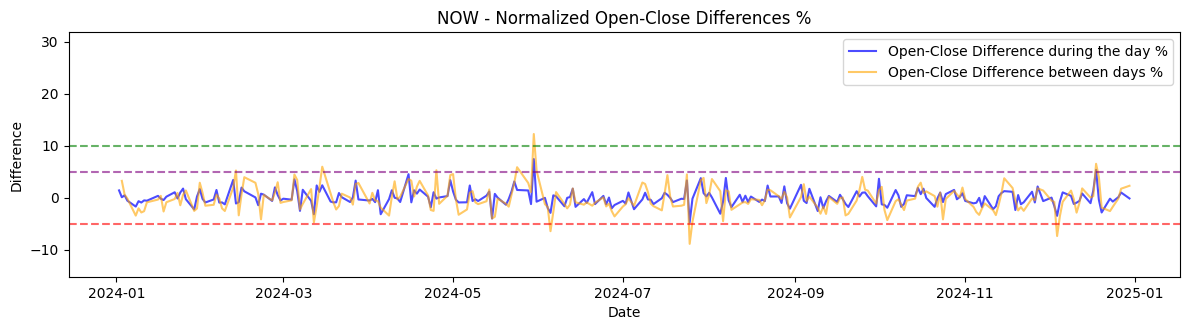

SHOP -> AVG Volume: 9,054,958, AVG price:77


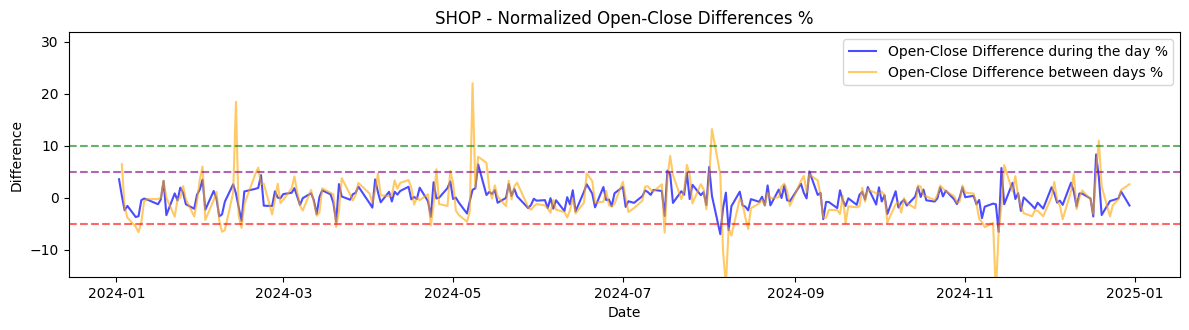

RIOT -> AVG Volume: 24,988,007, AVG price:10


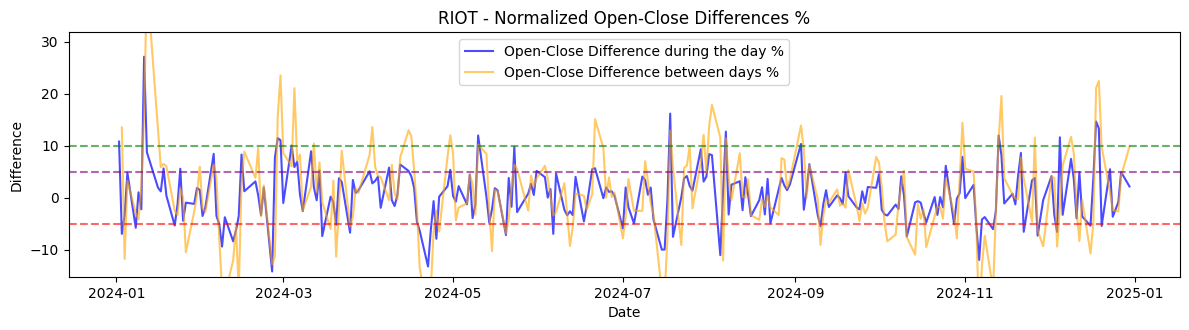

META -> AVG Volume: 14,717,144, AVG price:507


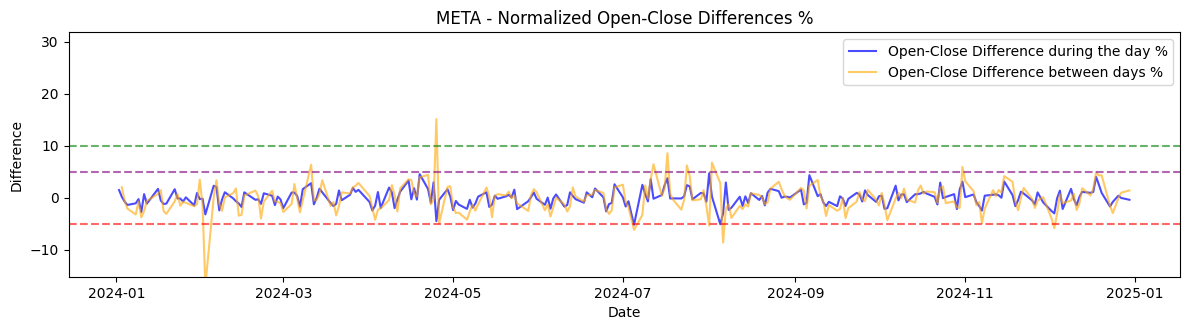

In [11]:
import matplotlib.pyplot as plt

idx = pd.IndexSlice

for ticker, data in volatility_per_ticker.items():
    mean_volume = format(int(stock_results.loc[:, idx['Volume', ticker]].mean()), ",")
    mean_close = format(int(stock_results.loc[:, idx['Close', ticker]].mean()), ",")
    print(f"{ticker} -> AVG Volume: {mean_volume}, AVG price:{mean_close}")
    
    plt.figure(figsize=(12,6))

    # plt.subplot(2, 1, 1)
    # data['high_low_diff_pct'].plot(title=f"{ticker} - Normalized High-Low Difference %", color="green")
    # plt.ylabel("High-Low Difference")
    plt.subplot(2, 1, 1)    
    # Overplay the two metrics
    plt.plot(data['open_close_diff_pct'], label="Open-Close Difference during the day %", color="blue", alpha=0.7)
    plt.plot(data['nextopen_close_diff_pct'], label="Open-Close Difference between days %", color="orange", alpha=0.6)
    # plt.ylim(y_pct_diff_min+10, y_pct_diff_max-10)

    plt.title(f"{ticker} - Normalized Open-Close Differences %")
    plt.ylabel("Difference")
    plt.xlabel("Date")
    plt.legend()
    
    plt.ylim(y_pct_diff_min+10, y_pct_diff_max-10)

    plt.axhline(10, color='green', linestyle='--', alpha=0.6)
    plt.axhline(5, color='purple', linestyle='--', alpha=0.6)
    plt.axhline(-5, color='red', linestyle='--', alpha=0.6)

    plt.tight_layout()

    plt.show()

If we analyze the relative changes independently of the dollar value, we see a different picture. This makes sense because smaller amounts can more easily result in larger percentage changes:
- RIOT has the highest volatility
- SHOP has some notable outsiders

Additionally, for the less volatile stocks, the highest peaks are almost always generated outside of market hours, and we rarely observe changes greater than 5%.

**Monotonity: see if the prices are growing in a relatively constant way**

In [12]:
min_close_y = stock_results.loc[:, idx['Close', :]].min()
print(f"minimum prices:\n{min_close_y}")

max_close_y = stock_results.loc[:, idx['Close', :]].max()
print(f"maximum prices:\n{max_close_y}")

minimum prices:
Price  Ticker
Close  LLY       589.334412
       META      343.159149
       NOW       643.289978
       RIOT        6.380000
       SHOP       52.259998
dtype: float64
maximum prices:
Price  Ticker
Close  LLY        960.020020
       META       632.170044
       NOW       1148.420044
       RIOT        17.620001
       SHOP       119.489998
dtype: float64


Let's see outliers and stability for the selected stocks.

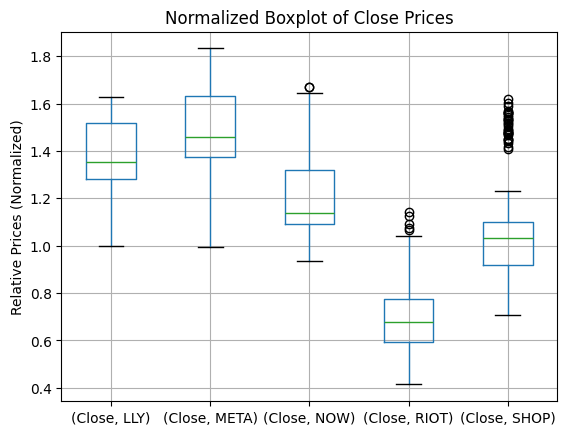

In [13]:
import matplotlib.pyplot as plt

# Normalized values for comparing growings relative to each other, and not to their value
normalized_data = stock_results.loc[:, idx['Close', :]].div(stock_results.loc[:, idx['Close', :]].iloc[0])
normalized_data.boxplot()
plt.title("Normalized Boxplot of Close Prices")
plt.ylabel("Relative Prices (Normalized)")
plt.show()

*Meaning of the Boxplot:*
- If the normalized price is greater than 1, it indicates growth over the past year; otherwise, it shows a decline.  
- Small box with long whiskers indicates higher volatility.  
- Large box with short whiskers indicates lower volatility.

**Stock categorization:**
- LLY and META: both show stable growth with a positive trend.
- NOW is in the middle; it has a growing tendency, but smaller, and it's not as stable as META and LLY
- RIOT and SHOP has a significant volatility, with many outliers. While we've already observed high volatility in RIOT, SHOP's extreme values may be explained by large price changes outside of trading hours.

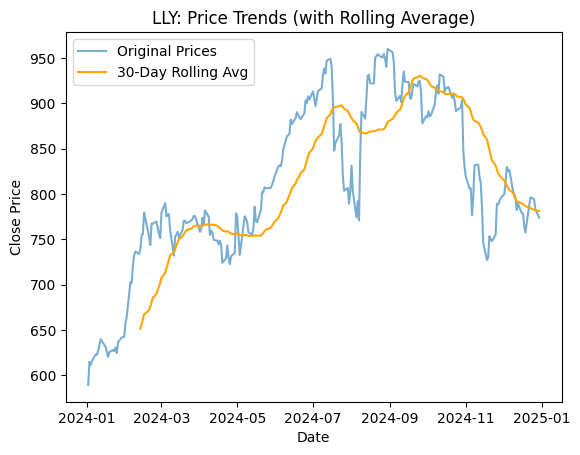

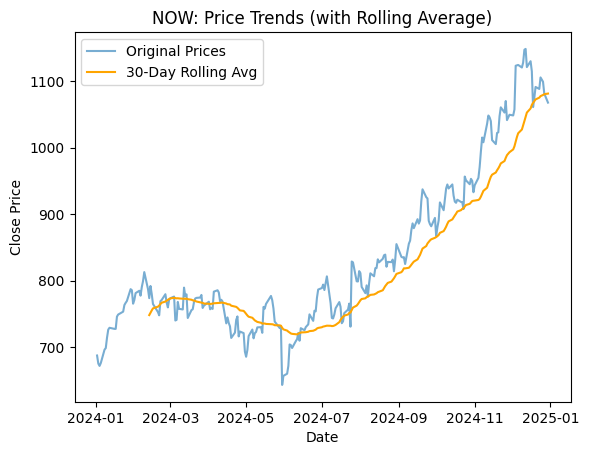

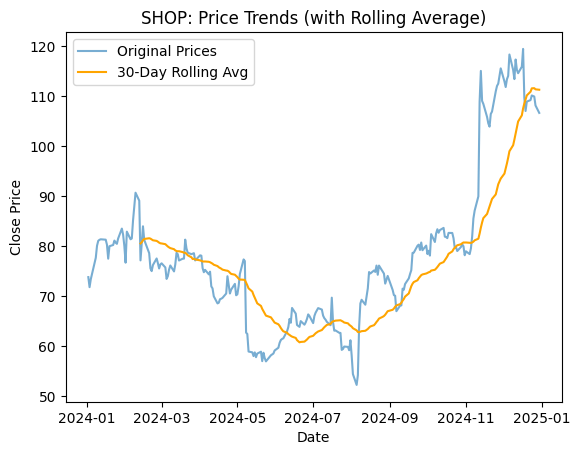

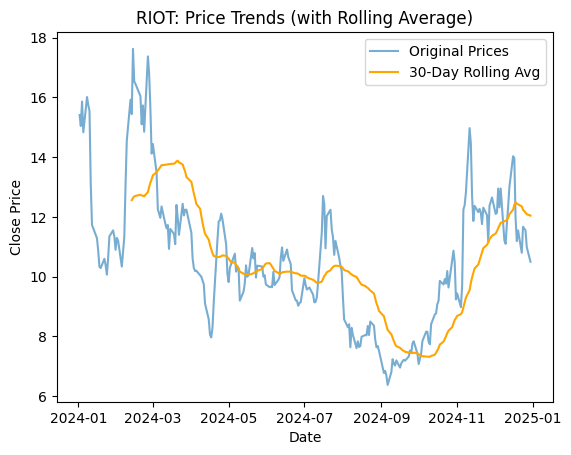

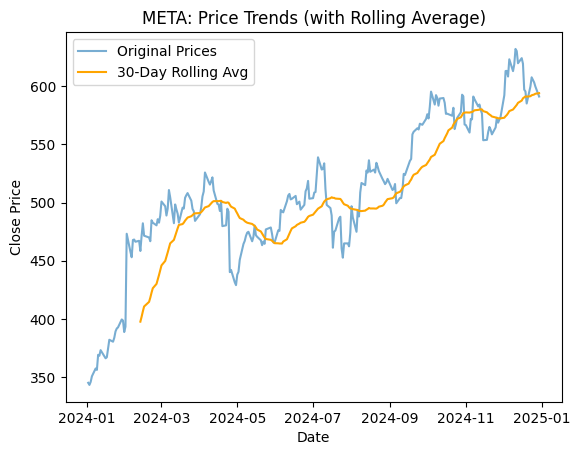

In [14]:
# Let's see the prices with a month-window rolling average!
for ticker in tickers:
    rolling_avg = stock_results.loc[:, ('Close', ticker)].rolling(window=30).mean()
    plt.plot(stock_results.loc[:, ('Close', ticker)], label="Original Prices", alpha=0.6)
    plt.plot(rolling_avg, label="30-Day Rolling Avg", color="orange")
    plt.title(f"{ticker}: Price Trends (with Rolling Average)")
    plt.xlabel("Date")
    plt.ylabel("Close Price")
    plt.legend()
    plt.show()

Over time, we can observe:
- META: shows stable growth with occasional smaller declines
- NOW and SHOP: demonstrates a growth as we finish the year, but with more volatility during the year
- LLY: was generally growing during the year, but has shown a declining tendency in recent months.
- RIOT: has been in a steady decline throughout the year

## Conclusions
- META has been the least volatile and demonstrated the most stable growth throughout the year
- LLY had low volatility and steady growth, though it started to show signs of decline towards the end of the year. It would make sense to analyze an additional year of data to better understand its long-term trend
- SHOP showed high volatility with large swings in price, and an upward trend during the last months
- NOW appears as a riskier investment choice, with more volatility and fluctuations in its performance
- RIOT showed a consistent decline throughout the year, indicating a potentially negative trend

## Possible improvements for the project
1. A web-scraper might be added to the pipeline which analyses articles of well-known websites that suggest financial assets for short-term investments.
2. The pipeline can be automated to pull data from the web scraper and evaluate performances, for example, daily
3. I’m only using stocks now, but it can be expanded with other types of securities like bonds, ETFs, etc.
4. Different short-term strategies can be explored and built into the code.
5. I might explore other data sources to clean and validate the data

## Difficulties with data
The data is well-structured, and for the one-year period analyzed, there were no major issues with missing or empty values. Handling multi-indexes was a bit more challenging, but after some practice, it became easier to manage.

## References
$^1$: https://www.investopedia.com/terms/s/shorterminvestments.asp  
$^2$: https://www.forbes.com/sites/investor-hub/article/best-growth-stocks/  
$^3$: https://pypi.org/project/yfinance/

In [15]:
pip freeze > requirements.txt

Note: you may need to restart the kernel to use updated packages.
